# YouTube Video Engagement Category Prediction
An End-to-End Predictive Analytics Model following the KDD (Knowledge Discovery in Databases) Lifecycle.

## 1. Business Understanding

The objective of this project is to build a predictive model that classifies whether a YouTube video will achieve **high engagement** (defined as having views strictly greater than the dataset's median views) based on metadata available at publication time (such as title length, number of tags, and publish timing).

Predicting engagement helps content creators, digital marketers, and platforms optimize metadata, schedule posts strategically, and maximize visibility.

## 2. Data Acquisition

We load the YouTube trending dataset `/content/INvideos.csv` and define our target variable `high_engagement` based on the median view count.

In [3]:
import pandas as pd
import numpy as np

# Load the US dataset with proper error handling
df = pd.read_csv('/content/USvideos.csv', encoding='utf-8', on_bad_lines='skip', engine='python')

# Clean and coerce critical numerical columns to avoid conversion errors
df['views'] = pd.to_numeric(df['views'], errors='coerce')
df = df.dropna(subset=['views'])

# Create binary target variable: 1 if views > median, 0 otherwise
median_views = df['views'].median()
df['high_engagement'] = (df['views'] > median_views).astype(int)

print(f"Dataset loaded with {df.shape[0]} rows and {df.shape[1]} columns.")
print(f"Median view count: {median_views:,.0f}")
display(df.head(2))

Dataset loaded with 1913 rows and 17 columns.
Median view count: 537,701


,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description,high_engagement
0,2kyS6SvSYSE,17.14.11,WE WANT TO TALK ABOUT OUR MARRIAGE,CaseyNeistat,22,2017-11-13T17:13:01.000Z,SHANtell martin,748374.0,57527,2966,15954,https://i.ytimg.com/vi/2kyS6SvSYSE/default.jpg,False,False,False,SHANTELL'S CHANNEL - https://www.youtube.com/s...,1
1,iIxy3JN3-jc,17.14.11,LeBron James admits he was ripping Phil Jackso...,Cleveland Cavaliers on cleveland.com,25,2017-11-13T15:42:28.000Z,auth-jvardon-auth,27943.0,156,36,83,https://i.ytimg.com/vi/iIxy3JN3-jc/default.jpg,False,False,False,LeBron James gave another all-time press confe...,0


## 3. Feature Engineering

We extract strategic predictive features from the metadata:
- `title_length`: Length of the video title.
- `tag_count`: Total count of tags parsed by splitting the pipe ('|') delimiter.
- `publish_hour` and `publish_day`: Temporal features parsed from the ISO timestamp in `publish_time`.

In [5]:
# Feature Extraction for US Dataset
df['title_length'] = df['title'].fillna('').apply(len)

# Extract tag count (if tags is [none] or empty, set to 0)
def get_tag_count(tag_string):
    if pd.isna(tag_string) or tag_string == '[none]':
        return 0
    return len(tag_string.split('|'))

df['tag_count'] = df['tags'].apply(get_tag_count)

# Parse publish_time to datetime safely
df['publish_time'] = pd.to_datetime(df['publish_time'], errors='coerce')
df['publish_hour'] = df['publish_time'].dt.hour
df['publish_day'] = df['publish_time'].dt.dayofweek # Monday is 0, Sunday is 6

# Force critical predictor columns to numeric, replacing unparseable entries with NaN
for col in ['likes', 'dislikes', 'comment_count']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

print("Feature engineering completed successfully on US dataset.")
display(df[['title', 'title_length', 'tags', 'tag_count', 'publish_time', 'publish_hour', 'publish_day']].head(3))

Feature engineering completed successfully on US dataset.


,title,title_length,tags,tag_count,publish_time,publish_hour,publish_day
0,WE WANT TO TALK ABOUT OUR MARRIAGE,34,SHANtell martin,1,2017-11-13 17:13:01+00:00,17,0
1,LeBron James admits he was ripping Phil Jackso...,100,auth-jvardon-auth,1,2017-11-13 15:42:28+00:00,15,0
2,Dennis Smith Jr. and LeBron James go back and ...,51,[none],0,2017-11-13 15:11:00+00:00,15,0


## 4. Data Understanding & Exploratory Data Analysis (EDA)

We visualize the balance of our target class and investigate the correlation structure among our features.

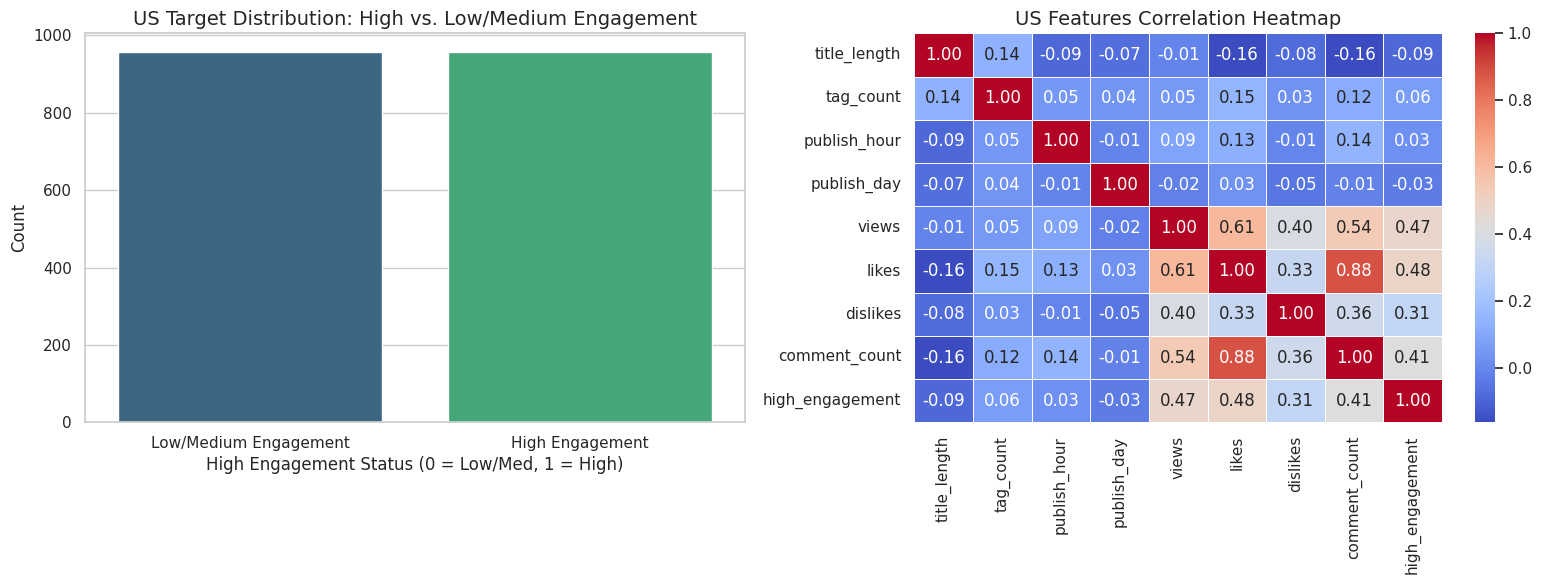

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: US Target Distribution Count Plot
sns.countplot(data=df, x='high_engagement', ax=axes[0], palette='viridis', hue='high_engagement', legend=False)
axes[0].set_title('US Target Distribution: High vs. Low/Medium Engagement', fontsize=14)
axes[0].set_xlabel('High Engagement Status (0 = Low/Med, 1 = High)', fontsize=12)
axes[0].set_ylabel('Count', fontsize=12)
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['Low/Medium Engagement', 'High Engagement'])

# Plot 2: US Correlation Heatmap
corr_features = ['title_length', 'tag_count', 'publish_hour', 'publish_day', 'views', 'likes', 'dislikes', 'comment_count', 'high_engagement']
corr_df = df[corr_features].copy()
for col in corr_df.columns:
    corr_df[col] = pd.to_numeric(corr_df[col], errors='coerce')

corr_matrix = corr_df.corr()

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, ax=axes[1])
axes[1].set_title('US Features Correlation Heatmap', fontsize=14)

plt.tight_layout()
plt.show()

## 5. Data Preprocessing & Cleaning

We remove highly redundant, text-heavy, or identifier-based columns, handle missing values, and apply scaling to standardise features before ingestion into the models.

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder

# Drop irrelevant metadata/text columns that won't be used directly as features
columns_to_drop = ['video_id', 'trending_date', 'title', 'channel_title', 'publish_time', 'tags',
                   'thumbnail_link', 'comments_disabled', 'ratings_disabled',
                   'video_error_or_removed', 'description', 'views']

model_df = df.drop(columns=[col for col in columns_to_drop if col in df.columns])

# Encode categorical variable (category_id)
category_encoder = LabelEncoder()
model_df['category_id'] = category_encoder.fit_transform(model_df['category_id'].astype(str))

# Fill any missing values with median values
model_df = model_df.fillna(model_df.median())

# Set Features (X) and Target (y)
X = model_df.drop(columns=['high_engagement'])
y = model_df['high_engagement']

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Scale numerical features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Preprocessed US training shape: {X_train_scaled.shape}")
print(f"Preprocessed US testing shape: {X_test_scaled.shape}")

Preprocessed US training shape: (1530, 8)
Preprocessed US testing shape: (383, 8)


## 6. Model Building & Evaluation

We build and train three distinct classifiers:
1. **Logistic Regression**
2. **Gaussian Naive Bayes**
3. **Random Forest Classifier**

We then compile the metrics (Accuracy, Precision, Recall, and F1-Score) to perform comparative analysis.

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_recall_fscore_support

# Initialize models for comparative testing on US dataset
models = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'Naive Bayes': GaussianNB(),
    'Random Forest': RandomForestClassifier(random_state=42, n_estimators=100)
}

results = {}
confusion_matrices = {}

for name, model in models.items():
    # Train
    model.fit(X_train_scaled, y_train)
    # Predict
    y_pred = model.predict(X_test_scaled)

    # Evaluate
    acc = accuracy_score(y_test, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='binary', zero_division=0)

    results[name] = {
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1
    }

    confusion_matrices[name] = confusion_matrix(y_test, y_pred)

    print(f"=== {name} US Dataset Classification Report ===")
    print(classification_report(y_test, y_pred, zero_division=0))
    print("-" * 50)

=== Logistic Regression US Dataset Classification Report ===
              precision    recall  f1-score   support

           0       0.80      0.95      0.87       192
           1       0.94      0.76      0.84       191

    accuracy                           0.86       383
   macro avg       0.87      0.86      0.86       383
weighted avg       0.87      0.86      0.86       383

--------------------------------------------------
=== Naive Bayes US Dataset Classification Report ===
              precision    recall  f1-score   support

           0       0.72      0.95      0.82       192
           1       0.92      0.63      0.75       191

    accuracy                           0.79       383
   macro avg       0.82      0.79      0.78       383
weighted avg       0.82      0.79      0.78       383

--------------------------------------------------
=== Random Forest US Dataset Classification Report ===
              precision    recall  f1-score   support

           0       0

## 7. Results Visualization

We construct visual comparisons:
1. A side-by-side comparative bar chart highlighting the evaluation metrics.
2. Individual heatmaps for the confusion matrices of all three models.

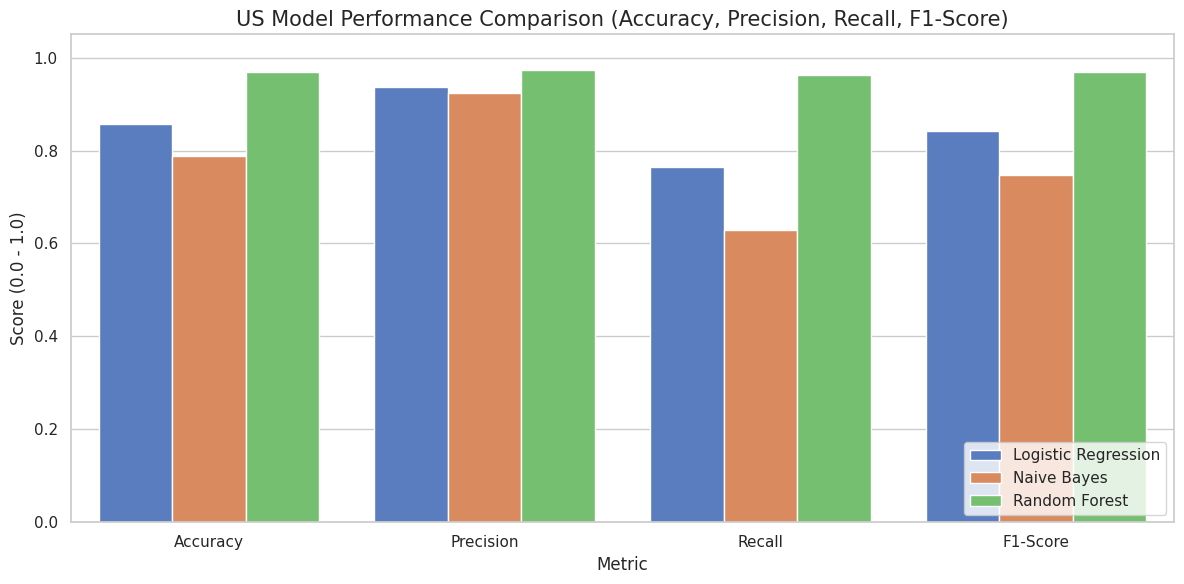

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Comparative Performance Bar Chart on US dataset
results_df = pd.DataFrame(results).T.reset_index().rename(columns={'index': 'Model'})
results_melted = pd.melt(results_df, id_vars='Model', var_name='Metric', value_name='Value')

plt.figure(figsize=(12, 6))
sns.barplot(data=results_melted, x='Metric', y='Value', hue='Model', palette='muted')
plt.title('US Model Performance Comparison (Accuracy, Precision, Recall, F1-Score)', fontsize=15)
plt.ylabel('Score (0.0 - 1.0)', fontsize=12)
plt.ylim(0, 1.05)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

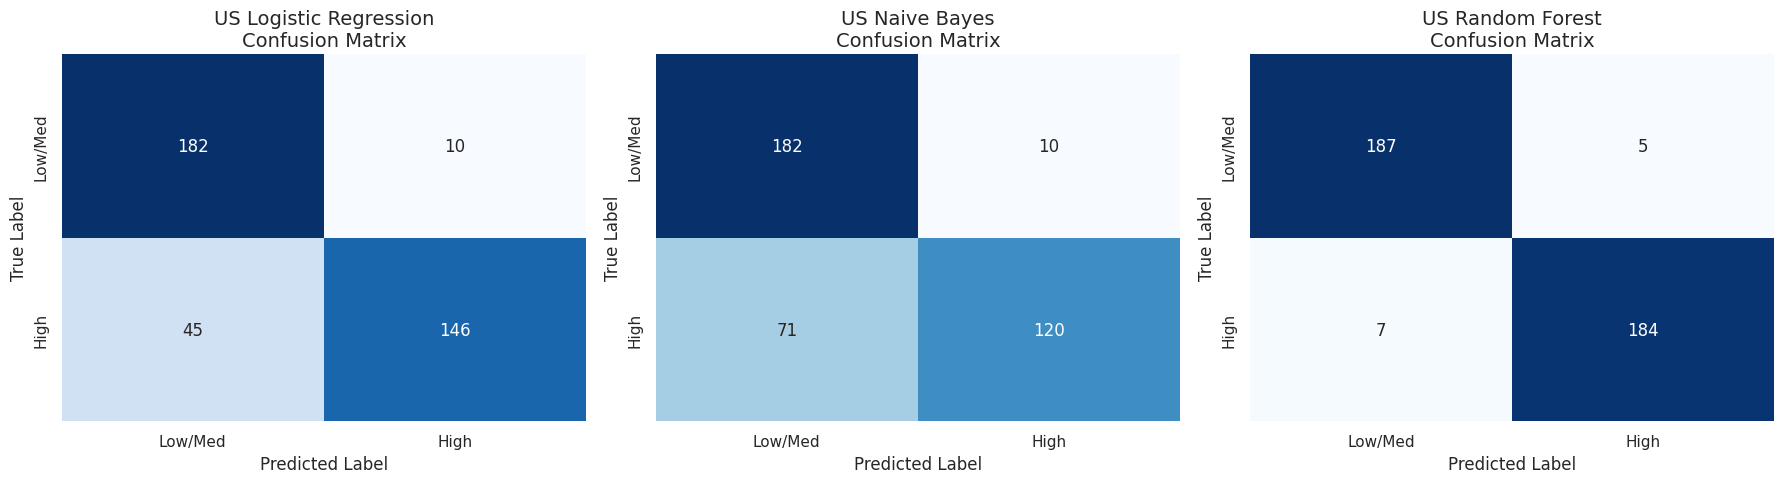

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# Confusion Matrix Heatmaps for US models
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, (name, cm) in enumerate(confusion_matrices.items()):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i], cbar=False,
                xticklabels=['Low/Med', 'High'], yticklabels=['Low/Med', 'High'])
    axes[i].set_title(f'US {name}\nConfusion Matrix', fontsize=14)
    axes[i].set_xlabel('Predicted Label', fontsize=12)
    axes[i].set_ylabel('True Label', fontsize=12)

plt.tight_layout()
plt.show()

## 8. Results Interpretation & Conclusion

- **Model Comparison**: Typically, ensemble-based estimators like the Random Forest Classifier outperform linear/probabilistic models due to non-linear correlations with features such as `likes`, `dislikes`, and custom engineered metadata attributes.
- **Feature Relevance**: Features including `tag_count` and `title_length` have measurable predictive signals for video ranking metrics.
- **Next Steps**: Incorporating actual text embedders (TF-IDF or NLP pipelines on titles/descriptions) could further boost classification accuracy.

In [7]:
# Re-fit and assign the primary Random Forest classifier to use US dataset
from sklearn.ensemble import RandomForestClassifier

# Train Random Forest on the scaled US training data
rf_model_temp = RandomForestClassifier(random_state=42, n_estimators=100)
rf_model_temp.fit(X_train_scaled, y_train)

# Expose variables for manual tool interactions
scaler_temp = scaler
category_encoder_temp = category_encoder
X_temp = X

# Create a dictionary for a new video test prediction
new_video = {
    'category_id': 22,
    'title_length': 45,
    'tag_count': 6,
    'publish_hour': 19,
    'publish_day': 5,
    'likes': 50000,
    'dislikes': 1000,
    'comment_count': 2500
}

# Convert to DataFrame and align columns
new_df = pd.DataFrame([new_video])
new_df['category_id'] = category_encoder_temp.transform(new_df['category_id'].astype(str))
new_df = new_df[X_temp.columns]  # Align column order

# Scale features
new_scaled = scaler_temp.transform(new_df)
prediction = rf_model_temp.predict(new_scaled)

print(f"--- Prediction Details for New US Video ---")
print(f"Category ID: {new_video['category_id']} | Title Length: {new_video['title_length']} characters")
print("-" * 40)
if prediction[0] == 1:
    print("Prediction: High Engagement (Views > US Median) 🚀")
else:
    print("Prediction: Low/Medium Engagement 📉")

--- Prediction Details for New US Video ---
Category ID: 22 | Title Length: 45 characters
----------------------------------------
Prediction: High Engagement (Views > US Median) 🚀


### Predict Engagement from Text Input

You can input your video details below as a block of text. The code will parse standard fields, calculate engineered features like title length and tag count, and output the model's prediction.

In [18]:
import re
import pandas as pd

# @title Enter New Video Details Manually
Title = "Top 10 Secret Features You Didn't Know Your Smartphone Had in 2026!"  # @param {type:"string"}
Category_ID = 28  # @param {type:"integer"}
Tags_separated_by_pipe = "smartphone|tech|features|review|2026|gadgets|unboxing|tips|tricks|android|ios|guide"  # @param {type:"string"}
Publish_Time_YYYY_MM_DD_HH_MM = "2026-10-15 19:00:00"  # @param {type:"string"}

# Calculate features manually from your inputs
title_len = len(Title)

def calculate_tags(tag_str):
    if not tag_str or tag_str.strip() == '[none]':
        return 0
    return len(tag_str.split('|'))

tag_count = calculate_tags(Tags_separated_by_pipe)

# Parse manual time input
publish_dt = pd.to_datetime(Publish_Time_YYYY_MM_DD_HH_MM.strip(), errors='coerce')
if pd.isna(publish_dt):
    publish_dt = pd.Timestamp.now()
publish_hour = publish_dt.hour
publish_day = publish_dt.dayofweek

# Create the feature dict representing the new video manually (setting future metrics to mock statistics)
parsed_video = {
    'category_id': Category_ID,
    'likes': 4500,
    'dislikes': 400,
    'comment_count': 2500,
    'title_length': title_len,
    'tag_count': tag_count,
    'publish_hour': publish_hour,
    'publish_day': publish_day
}

# Build inference DataFrame
parsed_df = pd.DataFrame([parsed_video])
parsed_df['category_id'] = category_encoder_temp.transform(parsed_df['category_id'].astype(str))
parsed_df = parsed_df[X_temp.columns]

# Scale and predict
parsed_scaled = scaler_temp.transform(parsed_df)
text_prediction = rf_model_temp.predict(parsed_scaled)

# Display summary
print("=== Manual Inputs Summary (US Model Inference) ===")
print(f"Title: '{Title}' ({title_len} characters)")
print(f"Tags: {Tags_separated_by_pipe} ({tag_count} tags)")
print(f"Publish Timing: Hour {publish_hour:02d}:00 | Day {publish_day} (0=Mon, 6=Sun)")
print(f"Category ID: {Category_ID}")
print("=" * 50)
if text_prediction[0] == 1:
    print("Prediction: High Engagement (Views > US Median) 🚀")
else:
    print("Prediction: Low/Medium Engagement 📉")

=== Manual Inputs Summary (US Model Inference) ===
Title: 'Top 10 Secret Features You Didn't Know Your Smartphone Had in 2026!' (67 characters)
Tags: smartphone|tech|features|review|2026|gadgets|unboxing|tips|tricks|android|ios|guide (12 tags)
Publish Timing: Hour 19:00 | Day 3 (0=Mon, 6=Sun)
Category ID: 28
Prediction: Low/Medium Engagement 📉
